# 12. Peso de Roca, Estabilidad de Escolleras y Filtros (`sedmor.armor`)

Este cuaderno ilustra las formulaciones más usadas en ingeniería marítima y fluvial para dimensionar coraza de roca y subcapas protectoras:

1. **Hudson (1959, 1974 / USACE SPM & CEM)**: masa mediana $M_{50}$ y diámetro nominal $D_{n50}$ mediante $K_D$.
2. **van der Meer (1988)** y **Van Gent et al. (2004) / *The Rock Manual* (CIRIA C683)**: estabilidad frente a oleaje irregular considerando rotura *plunging* vs. *surging*, permeabilidad nocional $P$, daño $S$, duración $N$ y aguas someras ($H_{2\%}$, $T_{m-1,0}$).
3. **Isbash (1936)**: peso mínimo de enrocado frente a corrientes rápidas y corrección por talud lateral.
4. Propiedades de capa, clasificación estándar **EN 13383** (`classify_rock_grading`) y verificación de filtros de **Terzaghi** (`filter_and_underlayer_design`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110


## 1. Comparación entre Hudson, van der Meer (1988) y Van Gent (2004)

Analizamos una escollera con talud $1\text{V}:2\text{H}$ ($\tan\alpha = 0.50$, $\cot\alpha = 2.0$), roca granítica de densidad $\rho_r = 2650\,\text{kg/m}^3$ en agua de mar ($1025\,\text{kg/m}^3$), permeabilidad $P = 0.4$ e inicio de daño ($S = 2.0$) para $N = 3000$ olas, variando el período de ola $T$.


Hudson (KD=2.0 rompiente): M50 = 9.12 t | Dn50 = 1.510 m
van der Meer (T=10 s, medio): M50 = 10.57 t | régimen = plunging
van der Meer (T=10 s, diseño): M50 = 17.92 t | clase = Escollera especial o prefabricado (> 15000 kg)
Van Gent someras (H2%=1.25 Hs, T=10 s): M50 = 8.30 t


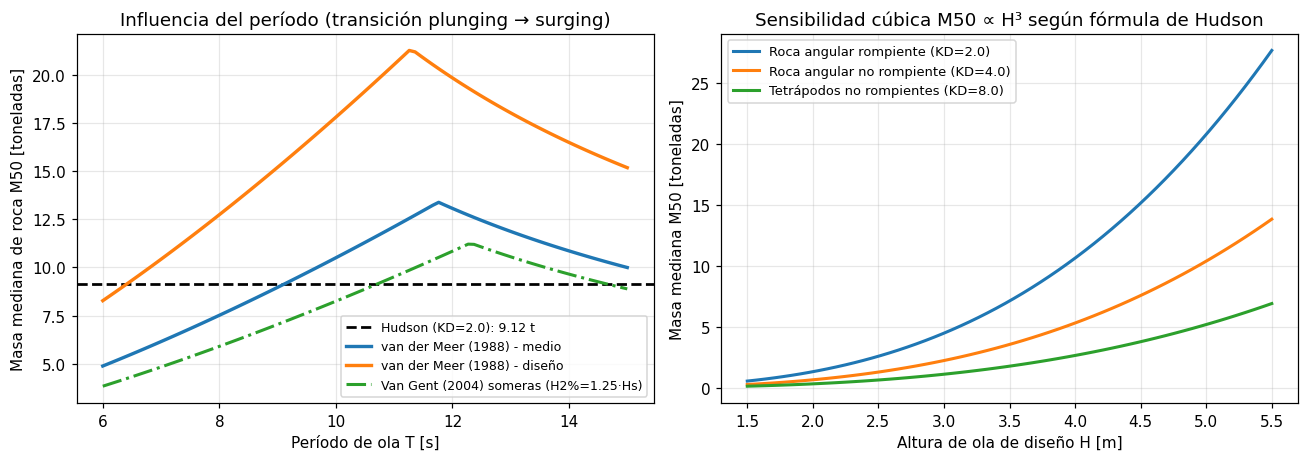

In [2]:
Hs = 3.8
slope = 0.50  # 1V:2H
periods = np.linspace(6.0, 15.0, 90)

hud = sm.armor.hudson_armor_weight(
    Hs, slope, KD=sm.armor.HUDSON_KD_VALUES["quarry_angular_rough_2_breaking_trunk"]
)
vdm_mean = sm.armor.van_der_meer_rock_armor(Hs, periods, slope, P=0.4, S=2.0, N=3000.0, approach="mean")
vdm_des = sm.armor.van_der_meer_rock_armor(Hs, periods, slope, P=0.4, S=2.0, N=3000.0, approach="design")
vg_sh = sm.armor.van_gent_shallow_rock_armor(
    Hs, periods, slope, H2_percent=1.25 * Hs, P=0.4, S=2.0, N=3000.0
)

idx_t10 = int(np.argmin(np.abs(periods - 10.0)))
print(f"Hudson (KD=2.0 rompiente): M50 = {hud.mass_tonnes:.2f} t | Dn50 = {hud.dn50_m:.3f} m")
print(f"van der Meer (T=10 s, medio): M50 = {vdm_mean.mass_tonnes[idx_t10]:.2f} t | régimen = {vdm_mean.regime[idx_t10]}")
print(f"van der Meer (T=10 s, diseño): M50 = {vdm_des.mass_tonnes[idx_t10]:.2f} t | clase = {sm.armor.classify_rock_grading(float(vdm_des.mass_kg[idx_t10]))['grading_class']}")
print(f"Van Gent someras (H2%=1.25 Hs, T=10 s): M50 = {vg_sh.mass_tonnes[idx_t10]:.2f} t")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))
ax1.axhline(hud.mass_tonnes, color="k", ls="--", lw=1.8, label=f"Hudson (KD=2.0): {hud.mass_tonnes:.2f} t")
ax1.plot(periods, vdm_mean.mass_tonnes, lw=2.2, label="van der Meer (1988) - medio")
ax1.plot(periods, vdm_des.mass_tonnes, lw=2.2, label="van der Meer (1988) - diseño")
ax1.plot(periods, vg_sh.mass_tonnes, "-.", lw=2.0, label="Van Gent (2004) someras (H2%=1.25·Hs)")
ax1.set_xlabel("Período de ola T [s]")
ax1.set_ylabel("Masa mediana de roca M50 [toneladas]")
ax1.set_title("Influencia del período (transición plunging → surging)")
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.2)

heights = np.linspace(1.5, 5.5, 60)
for name, kd in [
    ("Roca angular rompiente (KD=2.0)", 2.0),
    ("Roca angular no rompiente (KD=4.0)", 4.0),
    ("Tetrápodos no rompientes (KD=8.0)", 8.0),
]:
    res_h = sm.armor.hudson_armor_weight(heights, slope=0.50, KD=kd)
    ax2.plot(heights, res_h.mass_tonnes, lw=2.0, label=name)
ax2.set_xlabel("Altura de ola de diseño H [m]")
ax2.set_ylabel("Masa mediana M50 [toneladas]")
ax2.set_title("Sensibilidad cúbica M50 ∝ H³ según fórmula de Hudson")
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()


## 2. Enrocado bajo corrientes (Isbash) y diseño de subcapa y filtro

Calculamos el peso de escollera requerido frente a velocidades de corriente de $2.0$ a $5.0\,\text{m/s}$ mediante `isbash_stone_stability`, y dimensionamos la subcapa y el núcleo bajo nuestra coraza principal de diseño junto con la verificación de los criterios de filtro de Terzaghi (`filter_and_underlayer_design`).


Coraza: M50 = 17917 kg (Escollera especial o prefabricado (> 15000 kg)) | Dn50 = 1.891 m
Espesor 2 capas = 3.78 m | Rendimiento ≈ 0.35 piedras/m²
Subcapa: M50_u = 1493 kg | Dn50_u = 0.826 m | Espesor = 1.65 m
Núcleo: M50_core = 39.8 kg | Retención Terzaghi (D15/d85 <= 5): 4.24 (True)


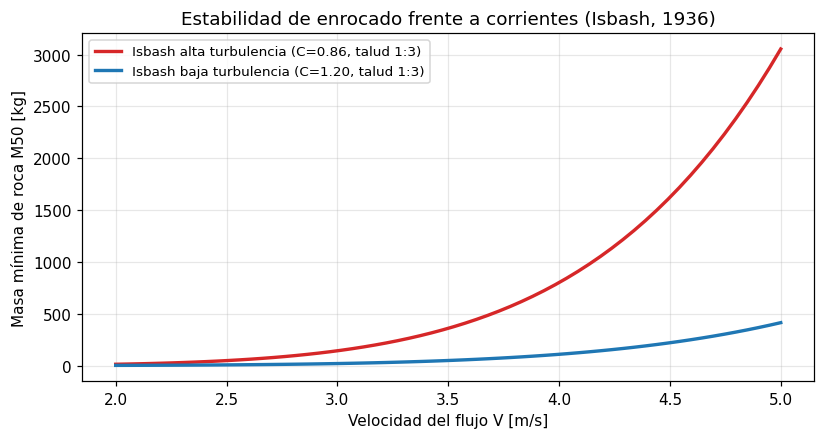

In [3]:
vels = np.linspace(2.0, 5.0, 60)
isb_hi = sm.armor.isbash_stone_stability(vels, regime="high_turbulence", slope=1.0 / 3.0)
isb_lo = sm.armor.isbash_stone_stability(vels, regime="low_turbulence", slope=1.0 / 3.0)

# Diseño completo multicapa a partir de van der Meer diseño (T=10 s)
m50_armor = float(vdm_des.mass_kg[idx_t10])
props = sm.armor.rock_size_properties(mass_kg=m50_armor)
clase = sm.armor.classify_rock_grading(m50_armor)
filt = sm.armor.filter_and_underlayer_design(
    m50_armor,
    armor_to_underlayer_ratio=12.0,
    armor_to_core_ratio=450.0,
    d15_subsoil_m=0.012,
    d85_subsoil_m=0.045,
)

print(f"Coraza: M50 = {props.mass_kg:.0f} kg ({clase['grading_class']}) | Dn50 = {props.dn50_m:.3f} m")
print(f"Espesor 2 capas = {props.layer_thickness_m:.2f} m | Rendimiento ≈ {props.stones_per_m2:.2f} piedras/m²")
print(f"Subcapa: M50_u = {filt.mass_underlayer_kg:.0f} kg | Dn50_u = {filt.dn50_underlayer_m:.3f} m | Espesor = {filt.thickness_underlayer_m:.2f} m")
print(f"Núcleo: M50_core = {filt.mass_core_kg:.1f} kg | Retención Terzaghi (D15/d85 <= 5): {filt.retention_ratio_d15_d85:.2f} ({filt.meets_terzaghi_retention})")

fig, ax = plt.subplots(figsize=(7.6, 4.1))
ax.plot(vels, isb_hi.mass_kg, lw=2.2, color="tab:red", label="Isbash alta turbulencia (C=0.86, talud 1:3)")
ax.plot(vels, isb_lo.mass_kg, lw=2.2, color="tab:blue", label="Isbash baja turbulencia (C=1.20, talud 1:3)")
ax.set_xlabel("Velocidad del flujo V [m/s]")
ax.set_ylabel("Masa mínima de roca M50 [kg]")
ax.set_title("Estabilidad de enrocado frente a corrientes (Isbash, 1936)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8.8)
plt.tight_layout()
plt.show()
